<a href="https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/work/notebooks/FlyRank_DuckDB_Missing_Data_Strategy_Benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FlyRank Full-Release DuckDB — Data Quality & Missing-Data Strategy Benchmark

**Purpose:** connect to the full FlyRank Hugging Face/DuckDB warehouse, audit data quality and measurement coverage, build a content-level feature table without converting unknown measurements into zeros, and compare imputation strategies before selecting a capstone default.

## Decision principles

1. Run SQL-based audits on the full warehouse before pulling modeling data into pandas.
2. Preserve observed zeros; distinguish them from missing or unavailable measurements.
3. Do not impute raw daily Search Console facts to manufacture a trend. Apply eligibility/coverage rules first.
4. Compare numerical imputation using artificial masking and reconstruction error. Fit imputers on training rows only.
5. Use a client-grouped downstream model comparison only as a secondary diagnostic, and only when the warehouse has a source `trend_direction` label. Do not treat that as proof of forecasting unless label timing is verified.
6. Export audit tables and the comparison summary. This notebook does not overwrite warehouse data.

**Expected runtime:** DuckDB scans the full daily fact table for date bounds and 60-day aggregation. Imputation benchmarks are capped to a reproducible sample because KNN and iterative imputation can be expensive at warehouse scale.

In [1]:
%pip -q install duckdb huggingface_hub pandas numpy scikit-learn matplotlib seaborn pyarrow

In [2]:
import os
from getpass import getpass
import json, warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, precision_score, recall_score, balanced_accuracy_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
OUTPUT_DIR = Path("outputs/flyrank_missing_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Authenticate and connect to the full-release warehouse

Uses the established FlyRank full-release connection pattern: read `HF_TOKEN` from the environment, then Colab Secrets, then a hidden prompt as a last resort; create the DuckDB Hugging Face secret; define the exact `REL` and `TABLES` paths; and verify each source with `COUNT(*)`. No token is printed or committed.

In [3]:
# Token order: environment variable -> Colab Secret -> hidden prompt (last resort).
# In Colab, create a Secret named HF_TOKEN in the key panel on the left.
HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass
HF_TOKEN = HF_TOKEN or getpass("Paste your Hugging Face READ token (hf_...): ")
if not HF_TOKEN:
    raise ValueError("HF_TOKEN is required to access the FlyRank warehouse.")

import duckdb
con = duckdb.connect()
# Use the same Hugging Face secret setup as the existing full-release notebook.
# Escape a quote in the token so it remains a valid SQL string literal.
safe_token = HF_TOKEN.replace("'", "''")
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{safe_token}')")

REL = 'hf://datasets/FlyRank/internship-warehouse'
TABLES = {
    'dim_clients':       f"read_parquet('{REL}/dim_clients.parquet')",
    'dim_content':       f"read_parquet('{REL}/dim_content.parquet')",
    'fact_daily':        f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    'fact_daily_sample': f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    'fact_query_90d':    f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}

# Test the same table paths used in the established full-release workflow.
for name, src in TABLES.items():
    n = con.sql(f'SELECT COUNT(*) FROM {src}').fetchone()[0]
    print(f'{name:22} {n:>12,} rows')


Paste your Hugging Face READ token (hf_...): ··········
dim_clients                     104 rows
dim_content                 519,606 rows


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

fact_daily               78,835,655 rows
fact_daily_sample        11,694,072 rows
fact_query_90d            2,414,248 rows


## 2. Inspect schemas and warehouse time coverage

This step discovers the actual columns rather than assuming that every CSV feature exists in the full release.

In [4]:
def describe_source(source_sql: str) -> pd.DataFrame:
    return con.execute(f"DESCRIBE SELECT * FROM {source_sql}").df()

schemas = {name: describe_source(sql) for name, sql in TABLES.items()}
for name, schema in schemas.items():
    print(f"\n{name}: {len(schema):,} columns")
    display(schema[[c for c in ["column_name", "column_type", "null", "key"] if c in schema.columns]])

content_cols = schemas["dim_content"]["column_name"].tolist()
daily_cols = schemas["fact_daily"]["column_name"].tolist()
query_cols = schemas["fact_query_90d"]["column_name"].tolist()

bounds = con.execute(f"""
SELECT MIN(report_date) AS min_report_date,
       MAX(report_date) AS max_report_date,
       COUNT(*) AS daily_fact_rows,
       COUNT(DISTINCT client_hash_id) AS clients,
       COUNT(DISTINCT content_hash_id) AS content_ids
FROM {TABLES['fact_daily']}
""").df()
display(bounds)


dim_clients: 9 columns


,column_name,column_type,null,key
0,client_hash_id,VARCHAR,YES,None
1,is_active,BOOLEAN,YES,None
2,has_gsc_access,BOOLEAN,YES,None
3,has_ga4_access,BOOLEAN,YES,None
4,access_profile,VARCHAR,YES,None
5,client_created_date,DATE,YES,None
6,client_updated_date,DATE,YES,None
7,gsc_data_start,DATE,YES,None
8,ga4_data_start,DATE,YES,None



dim_content: 26 columns


,column_name,column_type,null,key
0,client_hash_id,VARCHAR,YES,None
1,content_hash_id,VARCHAR,YES,None
2,keyword_hash_id,VARCHAR,YES,None
3,url_hash_id,VARCHAR,YES,None
4,keyword_char_count,BIGINT,YES,None
5,keyword_token_count,BIGINT,YES,None
6,url_char_count,BIGINT,YES,None
7,content_created_date,DATE,YES,None
8,content_updated_date,DATE,YES,None
9,content_type,VARCHAR,YES,None



fact_daily: 31 columns


...

,column_name,column_type,null,key
0,report_date,DATE,YES,None
1,client_hash_id,VARCHAR,YES,None
2,content_hash_id,VARCHAR,YES,None
3,client_has_gsc,BOOLEAN,YES,None
4,client_has_ga4,BOOLEAN,YES,None
5,gsc_data_available,BOOLEAN,YES,None
6,ga4_data_available,BOOLEAN,YES,None
7,gsc_impressions,BIGINT,YES,None
8,gsc_clicks,BIGINT,YES,None
9,gsc_sum_position,BIGINT,YES,None



fact_query_90d: 21 columns


,column_name,column_type,null,key
0,client_hash_id,VARCHAR,YES,None
1,content_hash_id,VARCHAR,YES,None
2,query_hash_id,VARCHAR,YES,None
3,query_char_count,BIGINT,YES,None
4,query_token_count,BIGINT,YES,None
5,window_start,DATE,YES,None
6,window_end,DATE,YES,None
7,impressions_90d,BIGINT,YES,None
8,clicks_90d,BIGINT,YES,None
9,impressions_last30,BIGINT,YES,None


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_report_date,max_report_date,daily_fact_rows,clients,content_ids
0,2025-01-27,2026-06-30,78835655,70,427292


## 3. Data-quality audit before imputation

The audit distinguishes a true recorded zero from a null. It also checks the content-dimension join key and reports missingness for the source tables. For the very large daily fact table, use SQL aggregates rather than loading raw records into pandas.

In [5]:
def quote_ident(name: str) -> str:
    return '"' + name.replace('"', '""') + '"'

def table_null_audit(source_sql: str, schema: pd.DataFrame, table_name: str) -> pd.DataFrame:
    cols = schema["column_name"].tolist()
    exprs = []
    for col in cols:
        q = quote_ident(col)
        exprs.append(f"COUNT(*) FILTER (WHERE {q} IS NULL) AS {quote_ident(col + '__nulls')}")
        if col in {"gsc_impressions", "gsc_clicks", "gsc_avg_position", "search_volume", "competition", "cpc", "word_count", "char_count"}:
            exprs.append(f"COUNT(*) FILTER (WHERE {q} = 0) AS {quote_ident(col + '__zeros')}")
    row = con.execute(f"SELECT COUNT(*) AS row_count, {', '.join(exprs)} FROM {source_sql}").df().iloc[0]
    records = []
    n = int(row["row_count"])
    for col in cols:
        nulls = int(row[col + "__nulls"])
        rec = {"table": table_name, "column": col, "rows": n, "null_count": nulls,
               "null_pct": 100 * nulls / n if n else np.nan}
        zero_key = col + "__zeros"
        if zero_key in row.index:
            rec["zero_count"] = int(row[zero_key])
            rec["zero_pct"] = 100 * int(row[zero_key]) / n if n else np.nan
        records.append(rec)
    return pd.DataFrame(records)

# Full dimension/query audits; daily fact uses the same SQL audit over the full source.
# This may scan the full fact table; run once and retain the exported audit.
audit_parts = []
for table_name in ["dim_content", "fact_query_90d"]:
    audit_parts.append(table_null_audit(TABLES[table_name], schemas[table_name], table_name))
# For daily facts, focus on identifiers and core measurement columns to avoid a wide expensive audit.
core_daily = [c for c in ["client_hash_id", "content_hash_id", "report_date", "gsc_impressions", "gsc_clicks", "gsc_avg_position"] if c in daily_cols]
daily_exprs = ["COUNT(*) AS row_count"]
for col in core_daily:
    q = quote_ident(col)
    daily_exprs.append(f"COUNT(*) FILTER (WHERE {q} IS NULL) AS {quote_ident(col + '__nulls')}")
    if col in {"gsc_impressions", "gsc_clicks", "gsc_avg_position"}:
        daily_exprs.append(f"COUNT(*) FILTER (WHERE {q} = 0) AS {quote_ident(col + '__zeros')}")
daily_row = con.execute(f"SELECT {', '.join(daily_exprs)} FROM {TABLES['fact_daily']}").df().iloc[0]
daily_records=[]
for col in core_daily:
    n=int(daily_row['row_count']); nulls=int(daily_row[col+'__nulls'])
    rec={"table":"fact_daily", "column":col, "rows":n, "null_count":nulls, "null_pct":100*nulls/n if n else np.nan}
    if col+'__zeros' in daily_row.index:
        rec['zero_count']=int(daily_row[col+'__zeros']); rec['zero_pct']=100*rec['zero_count']/n if n else np.nan
    daily_records.append(rec)
audit_parts.append(pd.DataFrame(daily_records))
missingness_audit = pd.concat(audit_parts, ignore_index=True)
missingness_audit = missingness_audit.sort_values(["table", "null_pct"], ascending=[True, False])
display(missingness_audit)
missingness_audit.to_csv(OUTPUT_DIR / "warehouse_missingness_audit.csv", index=False)
print("Saved:", OUTPUT_DIR / "warehouse_missingness_audit.csv")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table,column,rows,null_count,null_pct,zero_count,zero_pct
22,dim_content,last_optimized_date,519606,474210,91.263380,NaN,NaN
23,dim_content,optimization_eligible_date,519606,474210,91.263380,NaN,NaN
18,dim_content,provider_used,519606,369936,71.195483,NaN,NaN
15,dim_content,backlinks,519606,267474,51.476311,NaN,NaN
20,dim_content,char_count,519606,177768,34.212076,2.0,0.000385
21,dim_content,word_count,519606,177768,34.212076,2.0,0.000385
14,dim_content,main_intent,519606,148398,28.559716,NaN,NaN
12,dim_content,competition_level,519606,144456,27.801065,NaN,NaN
10,dim_content,search_volume,519606,142622,27.448105,163631.0,31.491361
11,dim_content,competition,519606,142622,27.448105,227867.0,43.853805


Saved: outputs/flyrank_missing_data/warehouse_missingness_audit.csv


### 3.1 Check content-key uniqueness before joining

The content dimension and query signals are joined by `content_hash_id` in the existing warehouse notebooks. Confirm that `dim_content` has one row per content key. The notebook stops rather than silently selecting arbitrary metadata if duplicate keys exist.

In [6]:
content_key_audit = con.execute(f"""
SELECT COUNT(*) AS rows,
       COUNT(content_hash_id) AS nonnull_content_keys,
       COUNT(DISTINCT content_hash_id) AS distinct_content_keys,
       COUNT(*) FILTER (WHERE content_hash_id IS NULL) AS null_content_keys
FROM {TABLES['dim_content']}
""").df()
display(content_key_audit)
content_key_stats = content_key_audit.iloc[0]
if int(content_key_stats["null_content_keys"]) > 0 or int(content_key_stats["rows"]) != int(content_key_stats["distinct_content_keys"]):
    raise ValueError(
        "dim_content is not unique on content_hash_id. Resolve/inspect duplicate content keys before joining metadata; "
        "do not use arbitrary ANY_VALUE metadata for the imputation benchmark."
    )
print("dim_content content_hash_id uniqueness check passed.")

,rows,nonnull_content_keys,distinct_content_keys,null_content_keys
0,519606,519606,519606,0


dim_content content_hash_id uniqueness check passed.


## 4. Build a content-level feature table in DuckDB

The daily fact table is aggregated in SQL before pandas is used. Importantly, sums of observed measurements remain `NULL` when a window has no observed values; we do not use `COALESCE(measurement, 0)` for the main features. The output also carries coverage counts so records with poor observation coverage can be excluded from trend-sensitive tasks.

In [7]:
# Metadata columns carried forward only when they exist in this release.
metadata_candidates = [
    "content_hash_id", "trend_direction", "content_type", "main_intent",
    "competition_level", "provider_used", "model_used", "search_volume",
    "competition", "cpc", "word_count", "char_count", "content_created_date"
]
metadata_available = [c for c in metadata_candidates if c in content_cols]
metadata_select = [f"c.{quote_ident(c)}" for c in metadata_available]
if "content_created_date" in content_cols:
    metadata_select.append("DATE_DIFF('day', CAST(c.content_created_date AS DATE), b.end_d) AS content_age_days")
metadata_select_sql = ",\n       ".join(metadata_select)

# Query signals are optional; only reference columns that are present.
q_candidates = {
    "content_visible_query_count": "visible_queries",
    "rare_impressions_share": "rare_share",
    "anonymized_impressions_share": "anon_share",
    "impressions_90d": "query_impressions_90d"
}
q_available = {src: out for src, out in q_candidates.items() if src in query_cols}
if q_available:
    q_select=[]
    for src, out in q_available.items():
        if src == "impressions_90d":
            q_select.append(f"SUM({quote_ident(src)}) AS {quote_ident(out)}")
            q_select.append(f"MAX({quote_ident(src)}) AS top_query_impressions")
        else:
            q_select.append(f"MAX({quote_ident(src)}) AS {quote_ident(out)}")
    qsignals_sql = f"""
    qsignals AS (
      SELECT content_hash_id, {', '.join(q_select)}
      FROM {TABLES['fact_query_90d']}
      GROUP BY content_hash_id
    ),
    """
    q_join = "LEFT JOIN qsignals q ON a.content_hash_id = q.content_hash_id"
    q_feature_select = [f"q.{quote_ident(out)}" for out in q_available.values()]
    if "impressions_90d" in q_available:
        q_feature_select += ["q.top_query_impressions", "q.top_query_impressions / NULLIF(q.query_impressions_90d, 0) AS top_query_share"]
    q_feature_select_sql = (",\n       " + ",\n       ".join(q_feature_select)) if q_feature_select else ""
else:
    qsignals_sql = ""
    q_join = ""
    q_feature_select_sql = ""

feature_sql = f"""
WITH bounds AS (
  SELECT MAX(CAST(report_date AS DATE)) AS end_d FROM {TABLES['fact_daily']}
),
daily_agg AS (
  SELECT f.client_hash_id, f.content_hash_id,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY) AS rows_last30,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY AND f.gsc_impressions IS NOT NULL) AS impressions_observed_last30,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY AND f.gsc_clicks IS NOT NULL) AS clicks_observed_last30,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY AND f.gsc_avg_position IS NOT NULL) AS position_observed_last30,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) <= b.end_d - INTERVAL 30 DAY AND CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY) AS rows_prev30,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) <= b.end_d - INTERVAL 30 DAY AND CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY AND f.gsc_impressions IS NOT NULL) AS impressions_observed_prev30,
    COUNT(*) FILTER (WHERE CAST(f.report_date AS DATE) <= b.end_d - INTERVAL 30 DAY AND CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY AND f.gsc_clicks IS NOT NULL) AS clicks_observed_prev30,
    SUM(CASE WHEN CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY THEN f.gsc_impressions END) AS imp_last30,
    SUM(CASE WHEN CAST(f.report_date AS DATE) <= b.end_d - INTERVAL 30 DAY AND CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY THEN f.gsc_impressions END) AS imp_prev30,
    SUM(CASE WHEN CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY THEN f.gsc_clicks END) AS clk_last30,
    SUM(CASE WHEN CAST(f.report_date AS DATE) <= b.end_d - INTERVAL 30 DAY AND CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY THEN f.gsc_clicks END) AS clk_prev30,
    AVG(CASE WHEN CAST(f.report_date AS DATE) > b.end_d - INTERVAL 30 DAY THEN f.gsc_avg_position END) AS pos_last30,
    AVG(CASE WHEN CAST(f.report_date AS DATE) <= b.end_d - INTERVAL 30 DAY AND CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY THEN f.gsc_avg_position END) AS pos_prev30,
    STDDEV_SAMP(f.gsc_avg_position) AS pos_volatility_60d,
    MAX(b.end_d) AS data_end_date
  FROM {TABLES['fact_daily']} f CROSS JOIN bounds b
  WHERE CAST(f.report_date AS DATE) > b.end_d - INTERVAL 60 DAY
  GROUP BY f.client_hash_id, f.content_hash_id
),
{qsignals_sql}
metadata AS (
  SELECT {', '.join(metadata_select)}
  FROM {TABLES['dim_content']} c CROSS JOIN bounds b
)
SELECT a.client_hash_id, a.content_hash_id, a.data_end_date,
       a.rows_last30, a.rows_prev30,
       a.impressions_observed_last30, a.impressions_observed_prev30,
       a.clicks_observed_last30, a.clicks_observed_prev30,
       a.position_observed_last30,
       a.imp_last30, a.imp_prev30, a.clk_last30, a.clk_prev30,
       a.pos_last30, a.pos_prev30, a.pos_volatility_60d,
       a.clk_last30 / NULLIF(a.imp_last30, 0) AS ctr_last30,
       a.clk_prev30 / NULLIF(a.imp_prev30, 0) AS ctr_prev30,
       (a.imp_last30 - a.imp_prev30) / NULLIF(a.imp_prev30, 0) AS trend_pct,
       a.pos_last30 - a.pos_prev30 AS position_change,
       {', '.join(['m.' + quote_ident(c) for c in metadata_available if c != 'content_hash_id'])}
       {q_feature_select_sql}
FROM daily_agg a
LEFT JOIN metadata m ON a.content_hash_id = m.content_hash_id
{q_join}
"""

print("Running content-level aggregation in DuckDB...")
features = con.execute(feature_sql).df()
print(f"Feature table: {len(features):,} rows × {len(features.columns):,} columns")
print("Data end date:", features["data_end_date"].max() if "data_end_date" in features else "unavailable")
display(features.head())

Running content-level aggregation in DuckDB...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Feature table: 409,326 rows × 38 columns
Data end date: 2026-06-30 00:00:00


,client_hash_id,content_hash_id,data_end_date,rows_last30,rows_prev30,impressions_observed_last30,impressions_observed_prev30,clicks_observed_last30,clicks_observed_prev30,position_observed_last30,imp_last30,imp_prev30,clk_last30,clk_prev30,pos_last30,pos_prev30,pos_volatility_60d,ctr_last30,ctr_prev30,trend_pct,position_change,content_type,main_intent,competition_level,provider_used,model_used,search_volume,competition,cpc,word_count,char_count,content_created_date,visible_queries,rare_share,anon_share,query_impressions_90d,top_query_impressions,top_query_share
0,client_04660893ae39614a,content_004de9653278b5a4,2026-06-30,30,7,30,7,30,7,0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,keyword article,transactional,HIGH,gemini-generate-content,gemini-3-flash-preview,30,0.91,0.98,2555,15682,2026-05-30,<NA>,NaN,NaN,NaN,<NA>,NaN
1,client_04660893ae39614a,content_00dc5efae381b2ab,2026-06-30,24,0,24,0,24,0,0,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,keyword article,commercial,LOW,gemini-generate-content,gemini-3-flash-preview,10,0.00,0.00,2430,15438,2026-06-12,<NA>,NaN,NaN,NaN,<NA>,NaN
2,client_04660893ae39614a,content_01410f2556c327ac,2026-06-30,30,10,30,10,30,10,0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,keyword article,informational,MEDIUM,gemini-generate-content,gemini-3-flash-preview,480,0.36,0.62,2645,16576,2026-05-09,<NA>,NaN,NaN,NaN,<NA>,NaN
3,client_04660893ae39614a,content_019f27f634053ca7,2026-06-30,21,0,21,0,21,0,0,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,keyword article,transactional,LOW,gemini-generate-content,gemini-3-flash-preview,0,0.00,0.00,2522,15457,2026-06-15,<NA>,NaN,NaN,NaN,<NA>,NaN
4,client_04660893ae39614a,content_01efa71faea45dcc,2026-06-30,30,10,30,10,30,10,0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,keyword article,transactional,HIGH,gemini-generate-content,gemini-3-flash-preview,2400,0.70,0.90,2552,15776,2026-05-21,<NA>,NaN,NaN,NaN,<NA>,NaN


## 5. Feature-table quality and eligibility audit

Do not impute low-coverage performance windows into apparently valid trends. These rules are reported as eligibility flags, not silently used to delete records. Tune thresholds only after reviewing the resulting coverage distribution.

In [8]:
id_cols = [c for c in ["client_hash_id", "content_hash_id"] if c in features.columns]
if id_cols != ["client_hash_id", "content_hash_id"]:
    raise KeyError("Expected client_hash_id and content_hash_id in the aggregated feature table.")

quality_records=[]
for col in features.columns:
    s=features[col]
    quality_records.append({
        "column": col,
        "dtype": str(s.dtype),
        "null_count": int(s.isna().sum()),
        "null_pct": float(100*s.isna().mean()),
        "n_unique_nonnull": int(s.nunique(dropna=True))
    })
feature_quality = pd.DataFrame(quality_records).sort_values("null_pct", ascending=False)
display(feature_quality)
feature_quality.to_csv(OUTPUT_DIR / "feature_table_quality.csv", index=False)

# Duplicate composite keys should be investigated rather than silently deduplicated.
duplicate_key_count = int(features.duplicated(id_cols).sum())
print("Duplicate client-content keys:", f"{duplicate_key_count:,}")
if duplicate_key_count:
    display(features.loc[features.duplicated(id_cols, keep=False), id_cols].head(20))
    raise ValueError("Aggregated feature table has duplicate client-content keys.")

# A conservative initial eligibility flag: at least 20 rows and at least 10 observed
# impression measurements in each 30-day window. These are configurable thresholds.
MIN_ROWS_PER_WINDOW = 20
MIN_IMPRESSIONS_OBSERVED_PER_WINDOW = 10
features["eligible_for_trend_analysis"] = (
    (features["rows_last30"] >= MIN_ROWS_PER_WINDOW) &
    (features["rows_prev30"] >= MIN_ROWS_PER_WINDOW) &
    (features["impressions_observed_last30"] >= MIN_IMPRESSIONS_OBSERVED_PER_WINDOW) &
    (features["impressions_observed_prev30"] >= MIN_IMPRESSIONS_OBSERVED_PER_WINDOW) &
    features["imp_last30"].notna() & features["imp_prev30"].notna()
)
print(features["eligible_for_trend_analysis"].value_counts(dropna=False).rename("rows"))
print("Eligible share:", round(100*features["eligible_for_trend_analysis"].mean(), 2), "%")

,column,dtype,null_count,null_pct,n_unique_nonnull
34,anon_share,float64,275474,67.299414,103451
35,query_impressions_90d,float64,275474,67.299414,11213
32,visible_queries,Int64,275474,67.299414,546
33,rare_share,float64,275474,67.299414,96498
37,top_query_share,float64,275474,67.299414,52509
36,top_query_impressions,Int64,275474,67.299414,5139
24,provider_used,object,266810,65.182764,9
20,position_change,float64,224587,54.867514,166798
17,ctr_last30,float64,200690,49.029380,25414
14,pos_last30,float64,200690,49.029380,149698


Duplicate client-content keys: 0
eligible_for_trend_analysis
True     373912
False     35414
Name: rows, dtype: int64
Eligible share: 91.35 %


## 6. Choose numeric/categorical columns for the imputation experiment

Identifiers, dates, coverage counters, the target, and target-derived trend features are not imputed as model predictors. The benchmark focuses on content metadata and search features that are eligible to be predictors. If `trend_direction` exists, it is treated as a label only and excluded from `X`.

In [9]:
# Target leakage exclusions. `trend_pct` is deliberately excluded from predictors because it
# can directly define a decline label or overlap the outcome window.
excluded_predictors = set(id_cols + [
    "data_end_date", "trend_direction", "trend_pct", "eligible_for_trend_analysis",
    "rows_last30", "rows_prev30", "impressions_observed_last30", "impressions_observed_prev30",
    "clicks_observed_last30", "clicks_observed_prev30", "position_observed_last30"
])

# Candidate predictor families. Keep only columns that actually exist in this warehouse.
preferred_numeric = [
    "imp_last30", "imp_prev30", "clk_last30", "clk_prev30", "pos_last30", "pos_prev30",
    "pos_volatility_60d", "ctr_last30", "ctr_prev30", "position_change", "content_age_days",
    "search_volume", "competition", "cpc", "word_count", "char_count",
    "visible_queries", "rare_share", "anon_share", "query_impressions_90d",
    "top_query_impressions", "top_query_share"
]
preferred_categorical = ["content_type", "main_intent", "competition_level", "provider_used", "model_used"]
numeric_cols = [c for c in preferred_numeric if c in features.columns and c not in excluded_predictors and pd.api.types.is_numeric_dtype(features[c])]
categorical_cols = [c for c in preferred_categorical if c in features.columns and c not in excluded_predictors]

# Remove numeric columns that are entirely missing; they cannot be imputed meaningfully.
all_missing_numeric = [c for c in numeric_cols if features[c].notna().sum() == 0]
numeric_cols = [c for c in numeric_cols if c not in all_missing_numeric]
print("Numeric predictors:", numeric_cols)
print("Categorical predictors:", categorical_cols)
print("Dropped all-missing numeric columns:", all_missing_numeric)
if not numeric_cols:
    raise ValueError("No usable numeric features found. Inspect schema and update preferred_numeric.")

Numeric predictors: ['imp_last30', 'imp_prev30', 'clk_last30', 'clk_prev30', 'pos_last30', 'pos_prev30', 'pos_volatility_60d', 'ctr_last30', 'ctr_prev30', 'position_change', 'search_volume', 'competition', 'cpc', 'word_count', 'char_count', 'visible_queries', 'rare_share', 'anon_share', 'query_impressions_90d', 'top_query_impressions', 'top_query_share']
Categorical predictors: ['content_type', 'main_intent', 'competition_level', 'provider_used', 'model_used']
Dropped all-missing numeric columns: []


## 7. Reproducible imputation comparison using artificial masking

This is the primary comparison and does not require a target label. A fraction of observed values in the held-out rows is artificially masked; each imputer is fitted on training rows only. We score only cells that were observed before artificial masking.

- **Median:** robust, fast baseline.
- **KNN:** distance-based alternative; numeric features are standardized before imputation.
- **Iterative:** multivariate alternative; numeric features are standardized before imputation.

The benchmark sample cap controls compute cost. Increase it after confirming runtime and memory usage.

In [10]:
MAX_BENCHMARK_ROWS = 20000
MASK_FRACTION = 0.10
MAX_ITERATIVE_FEATURES = 25

benchmark_df = features.loc[features[numeric_cols].notna().any(axis=1), id_cols + numeric_cols].copy()
if len(benchmark_df) > MAX_BENCHMARK_ROWS:
    benchmark_df = benchmark_df.sample(n=MAX_BENCHMARK_ROWS, random_state=RANDOM_STATE)
benchmark_df = benchmark_df.reset_index(drop=True)

# Random row split is used for the imputation reconstruction task, not for the final
# generalization estimate. Imputer fit/transform separation still prevents row leakage.
rng = np.random.default_rng(RANDOM_STATE)
perm = rng.permutation(len(benchmark_df))
split = max(1, int(0.75 * len(benchmark_df)))
train_idx, test_idx = perm[:split], perm[split:]
X_num = benchmark_df[numeric_cols].replace([np.inf, -np.inf], np.nan).astype(float)
X_train = X_num.iloc[train_idx].copy()
X_test_original = X_num.iloc[test_idx].copy()

mask_rng = np.random.default_rng(RANDOM_STATE + 1)
artificial_mask = pd.DataFrame(False, index=X_test_original.index, columns=numeric_cols)
X_test_masked = X_test_original.copy()
for col in numeric_cols:
    observed_idx = X_test_original.index[X_test_original[col].notna()].to_numpy()
    n_mask = int(np.floor(len(observed_idx) * MASK_FRACTION))
    if n_mask:
        chosen = mask_rng.choice(observed_idx, size=n_mask, replace=False)
        artificial_mask.loc[chosen, col] = True
        X_test_masked.loc[chosen, col] = np.nan

masked_cells = int(artificial_mask.to_numpy().sum())
print(f"Benchmark rows={len(benchmark_df):,}; train={len(X_train):,}; test={len(X_test_original):,}; artificially masked observed cells={masked_cells:,}")
if masked_cells == 0:
    raise ValueError("No observed cells were available for artificial masking; inspect feature missingness.")

Benchmark rows=20,000; train=15,000; test=5,000; artificially masked observed cells=6,439


In [11]:
def reconstruction_metrics(method_name, original, imputed, mask):
    y_true = original.where(mask).stack().to_numpy(dtype=float)
    y_pred = imputed.where(mask).stack().to_numpy(dtype=float)
    if len(y_true) == 0:
        return {"method": method_name, "masked_cells": 0, "MAE": np.nan, "RMSE": np.nan}
    err = y_pred - y_true
    return {"method": method_name, "masked_cells": len(y_true),
            "MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err**2)))}

def fit_transform_scaled_imputer(train, test_masked, kind):
    # StandardScaler handles NaNs by ignoring them in fit and preserving them in transform.
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train)
    test_scaled = scaler.transform(test_masked)
    if kind == "knn":
        imputer = KNNImputer(n_neighbors=5, weights="distance")
    elif kind == "iterative":
        imputer = IterativeImputer(max_iter=10, random_state=RANDOM_STATE,
                                   initial_strategy="median", tol=1e-3, skip_complete=True)
    else:
        raise ValueError(kind)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        train_imp = imputer.fit_transform(train_scaled)
        test_imp = imputer.transform(test_scaled)
    return (scaler.inverse_transform(train_imp), scaler.inverse_transform(test_imp),
            [str(w.message) for w in caught])

imputation_results=[]
imputed_test_by_method={}

# Median baseline.
median_imp = SimpleImputer(strategy="median")
median_imp.fit(X_train)
median_test = pd.DataFrame(median_imp.transform(X_test_masked), index=X_test_masked.index, columns=numeric_cols)
imputed_test_by_method["median"] = median_test
imputation_results.append(reconstruction_metrics("Median", X_test_original, median_test, artificial_mask))

# KNN alternative.
knn_train_array, knn_test_array, knn_warnings = fit_transform_scaled_imputer(X_train, X_test_masked, "knn")
knn_test = pd.DataFrame(knn_test_array, index=X_test_masked.index, columns=numeric_cols)
imputed_test_by_method["knn"] = knn_test
imputation_results.append(reconstruction_metrics("KNN (scaled, k=5)", X_test_original, knn_test, artificial_mask))

# Iterative alternative.
iter_train_array, iter_test_array, iter_warnings = fit_transform_scaled_imputer(X_train, X_test_masked, "iterative")
iter_test = pd.DataFrame(iter_test_array, index=X_test_masked.index, columns=numeric_cols)
imputed_test_by_method["iterative"] = iter_test
imputation_results.append(reconstruction_metrics("Iterative (scaled)", X_test_original, iter_test, artificial_mask))

imputation_comparison = pd.DataFrame(imputation_results).sort_values("MAE")
display(imputation_comparison)
if knn_warnings:
    print("KNN warnings:", knn_warnings[:5])
if iter_warnings:
    print("Iterative imputer warnings:", iter_warnings[:5])
imputation_comparison.to_csv(OUTPUT_DIR / "imputation_reconstruction_comparison.csv", index=False)
print("Saved:", OUTPUT_DIR / "imputation_reconstruction_comparison.csv")

,method,masked_cells,MAE,RMSE
1,"KNN (scaled, k=5)",6439,220.130049,1584.475724
2,Iterative (scaled),6439,251.165680,1206.334129
0,Median,6439,495.365898,2302.719109


Iterative imputer warnings: ['[IterativeImputer] Early stopping criterion not reached.']
Saved: outputs/flyrank_missing_data/imputation_reconstruction_comparison.csv


### 7.1 Error by feature

Aggregate scores can hide poor imputation on a small number of important fields. This table reports the reconstruction MAE by feature and method. Since features use different units, compare methods within a feature rather than comparing raw MAE across different features.

,method,feature,masked_cells,MAE,RMSE
38,knn,anon_share,158,0.125943,0.179874
59,iterative,anon_share,158,0.128466,0.168929
17,median,anon_share,158,0.204032,0.257356
56,iterative,char_count,367,1346.724226,2730.425488
35,knn,char_count,367,1578.484940,3191.538447
14,median,char_count,367,5471.817439,7179.106732
23,knn,clk_last30,499,1.210155,7.339058
2,median,clk_last30,499,1.460922,6.206048
44,iterative,clk_last30,499,3.177734,14.278138
24,knn,clk_prev30,473,1.651048,11.310800


<Figure size 1200x735 with 0 Axes>

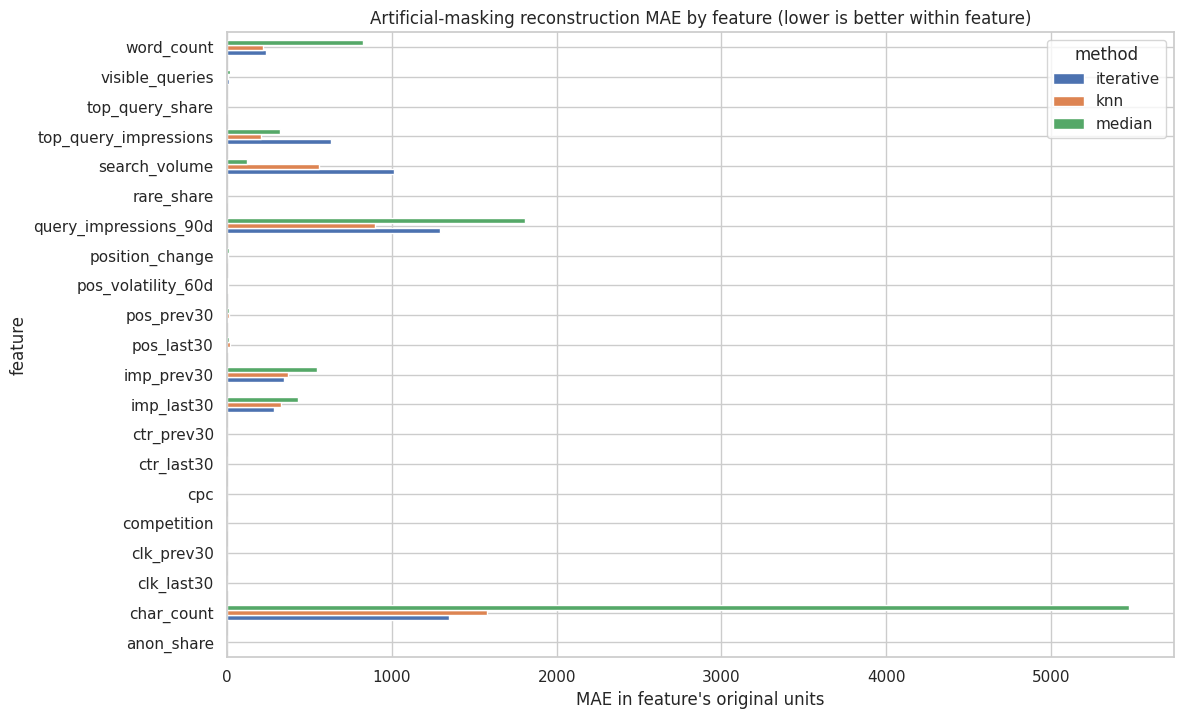

In [12]:
per_feature_rows=[]
for method, imputed in imputed_test_by_method.items():
    for col in numeric_cols:
        m = artificial_mask[col]
        if int(m.sum()) == 0:
            continue
        truth = X_test_original.loc[m, col].to_numpy(dtype=float)
        pred = imputed.loc[m, col].to_numpy(dtype=float)
        per_feature_rows.append({"method": method, "feature": col, "masked_cells": len(truth),
                                 "MAE": float(np.mean(np.abs(pred-truth))),
                                 "RMSE": float(np.sqrt(np.mean((pred-truth)**2)))})
per_feature_comparison = pd.DataFrame(per_feature_rows)
display(per_feature_comparison.sort_values(["feature", "MAE"]))
per_feature_comparison.to_csv(OUTPUT_DIR / "imputation_reconstruction_by_feature.csv", index=False)

plt.figure(figsize=(12, max(4, 0.35*len(numeric_cols))))
plot_df = per_feature_comparison.pivot(index="feature", columns="method", values="MAE")
plot_df.plot(kind="barh", figsize=(12, max(4, 0.35*len(numeric_cols))))
plt.title("Artificial-masking reconstruction MAE by feature (lower is better within feature)")
plt.xlabel("MAE in feature's original units")
plt.tight_layout()
plt.show()

## 8. Optional downstream classification comparison

This section runs only if the full-release content dimension contains a usable source `trend_direction` label. It is a secondary diagnostic: the label's time semantics must be verified before interpreting the results as early-warning performance. `trend_pct` is excluded from predictors. Client grouping is used so pages from a client do not appear in both train and test sets.

The imputation methods compared here are median, KNN, and iterative for numeric fields; categorical fields use an explicit missing category in all three pipelines. This keeps the comparison focused on numeric imputation. If there is no source label, skip this section and choose based on reconstruction diagnostics plus domain validity.

In [13]:
target_col = "trend_direction"
classification_results=[]
if target_col not in features.columns:
    print("Skipping downstream classification: no source trend_direction column in dim_content.")
elif features[target_col].notna().sum() == 0:
    print("Skipping downstream classification: trend_direction is entirely missing.")
else:
    model_numeric = [c for c in numeric_cols if c in features.columns]
    model_cat = [c for c in categorical_cols if features[c].notna().any()]
    model_cols = id_cols + [target_col] + model_numeric + model_cat
    model_df = features[model_cols].copy()
    model_df = model_df[model_df[target_col].notna() & model_df["client_hash_id"].notna()].copy()
    model_df["is_declining"] = model_df[target_col].astype(str).str.strip().str.lower().isin(["down", "declining", "decline"]).astype(int)
    if model_df["is_declining"].nunique() < 2 or model_df["client_hash_id"].nunique() < 2:
        print("Skipping downstream classification: insufficient label classes or client groups.")
    else:
        # Cap the model comparison for notebook runtime. Sample after retaining client IDs.
        MAX_MODEL_ROWS = 100000
        if len(model_df) > MAX_MODEL_ROWS:
            model_df = model_df.sample(n=MAX_MODEL_ROWS, random_state=RANDOM_STATE)
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
        train_pos, test_pos = next(splitter.split(model_df, model_df["is_declining"], groups=model_df["client_hash_id"]))
        train_df, test_df = model_df.iloc[train_pos].copy(), model_df.iloc[test_pos].copy()
        Xtr, Xte = train_df[model_numeric + model_cat], test_df[model_numeric + model_cat]
        ytr, yte = train_df["is_declining"], test_df["is_declining"]
        print(f"Grouped model rows: train={len(train_df):,}, test={len(test_df):,}; train clients={train_df.client_hash_id.nunique()}, test clients={test_df.client_hash_id.nunique()}")
        overlap = set(train_df.client_hash_id) & set(test_df.client_hash_id)
        assert not overlap, "Client leakage detected in grouped split."

        def make_preprocessor(numeric_method):
            if numeric_method == "median":
                num_imp = SimpleImputer(strategy="median", add_indicator=True)
            elif numeric_method == "knn":
                num_imp = Pipeline([("scale", StandardScaler()), ("imputer", KNNImputer(n_neighbors=5, weights="distance"))])
            elif numeric_method == "iterative":
                num_imp = Pipeline([("scale", StandardScaler()), ("imputer", IterativeImputer(max_iter=10, random_state=RANDOM_STATE, initial_strategy="median", skip_complete=True))])
            else:
                raise ValueError(numeric_method)
            transformers = []
            if model_numeric:
                transformers.append(("num", num_imp, model_numeric))
            if model_cat:
                cat_pipe = Pipeline([
                    ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ])
                transformers.append(("cat", cat_pipe, model_cat))
            return ColumnTransformer(transformers=transformers, remainder="drop")

        for method in ["median", "knn", "iterative"]:
            try:
                clf = Pipeline([
                    ("prep", make_preprocessor(method)),
                    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                                      class_weight="balanced", random_state=RANDOM_STATE,
                                                      n_jobs=-1))
                ])
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    clf.fit(Xtr, ytr)
                    pred = clf.predict(Xte)
                classification_results.append({
                    "method": method,
                    "rows_train": len(train_df), "rows_test": len(test_df),
                    "clients_train": train_df.client_hash_id.nunique(),
                    "clients_test": test_df.client_hash_id.nunique(),
                    "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
                    "balanced_accuracy": balanced_accuracy_score(yte, pred),
                    "decline_precision": precision_score(yte, pred, zero_division=0),
                    "decline_recall": recall_score(yte, pred, zero_division=0),
                    "warnings": " | ".join(str(w.message) for w in caught[:2])
                })
            except Exception as exc:
                classification_results.append({"method": method, "error": repr(exc)})
        classification_comparison = pd.DataFrame(classification_results)
        display(classification_comparison)
        classification_comparison.to_csv(OUTPUT_DIR / "downstream_classification_imputation_comparison.csv", index=False)
        print("Saved:", OUTPUT_DIR / "downstream_classification_imputation_comparison.csv")

Skipping downstream classification: no source trend_direction column in dim_content.


## 9. Categorical missingness audit

For categorical features, the primary deployment candidate is an explicit missing category (`__MISSING__`) followed by one-hot encoding. This preserves the fact that metadata was unavailable. Do not impute `provider_used` or `model_used` to a common real category unless the missingness mechanism is understood and the downstream experiment justifies that choice.

In [14]:
categorical_audit_rows=[]
for col in categorical_cols:
    s=features[col]
    categorical_audit_rows.append({
        "feature": col,
        "rows": len(s),
        "missing_count": int(s.isna().sum()),
        "missing_pct": float(100*s.isna().mean()),
        "distinct_nonmissing": int(s.nunique(dropna=True)),
        "top_category": str(s.mode(dropna=True).iloc[0]) if not s.mode(dropna=True).empty else None,
        "top_category_count": int(s.value_counts(dropna=True).iloc[0]) if not s.value_counts(dropna=True).empty else 0
    })
categorical_missingness = pd.DataFrame(categorical_audit_rows)
display(categorical_missingness)
categorical_missingness.to_csv(OUTPUT_DIR / "categorical_missingness_audit.csv", index=False)

,feature,rows,missing_count,missing_pct,distinct_nonmissing,top_category,top_category_count
0,content_type,409326,0,0.000000,3,keyword article,349387
1,main_intent,409326,71576,17.486307,4,informational,236627
2,competition_level,409326,67896,16.587268,3,LOW,284610
3,provider_used,409326,266810,65.182764,9,google,69171
4,model_used,409326,84963,20.756805,5,gemini-3-flash-preview,167517


## 10. Select a candidate and write a deployment recommendation

Do not automatically choose the method with the lowest single aggregate score. Consider per-feature reconstruction error, stability, runtime, missingness semantics, and (when available) grouped downstream performance. Median is the default unless the experiment shows a consistent and meaningful gain for a more complex method.

In [15]:
# Summary recommendation based on the artificial-masking benchmark only.
# Reconstruction MAE is reported in original units; the per-feature table is needed because
# a few high-scale variables can dominate the aggregate.
ranked = imputation_comparison.sort_values(["MAE", "RMSE"]).reset_index(drop=True)
median_row = ranked.loc[ranked["method"] == "Median"]
if not median_row.empty and len(ranked):
    best = ranked.iloc[0]
    med = median_row.iloc[0]
    if best["method"] != "Median" and best["MAE"] < med["MAE"] * 0.95:
        recommendation = f"Investigate {best['method']} as a candidate: aggregate masked-cell MAE is at least 5% lower than median. Confirm per-feature performance, runtime, and downstream grouped evaluation before deployment."
    else:
        recommendation = "Use median imputation plus missingness indicators as the default numeric baseline. No alternative has demonstrated a sufficiently large aggregate MAE gain to justify automatic deployment; review per-feature and downstream results."
else:
    recommendation = "Use median imputation plus missingness indicators as the initial baseline, then inspect the exported diagnostics before final selection."
print("RECOMMENDATION:", recommendation)

run_manifest = {
    "warehouse": REL,
    "data_end_date": str(features["data_end_date"].max()) if "data_end_date" in features else None,
    "rows_in_feature_table": int(len(features)),
    "feature_columns": list(features.columns),
    "numeric_imputation_candidates": ["median", "KNNImputer(n_neighbors=5, weights='distance')", "IterativeImputer(max_iter=10)"],
    "categorical_strategy": "constant __MISSING__ + OneHotEncoder(handle_unknown='ignore')",
    "random_state": RANDOM_STATE,
    "benchmark_sample_rows": int(len(benchmark_df)),
    "artificial_mask_fraction": MASK_FRACTION,
    "recommendation": recommendation,
    "caveat": "Reconstruction benchmark uses artificially masked observed values; downstream classification is diagnostic and not proof of future forecasting unless target timing is validated."
}
with open(OUTPUT_DIR / "run_manifest.json", "w", encoding="utf-8") as f:
    json.dump(run_manifest, f, indent=2)
print("Saved outputs under:", OUTPUT_DIR.resolve())
print("Files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print(" -", p.name)

RECOMMENDATION: Investigate KNN (scaled, k=5) as a candidate: aggregate masked-cell MAE is at least 5% lower than median. Confirm per-feature performance, runtime, and downstream grouped evaluation before deployment.
Saved outputs under: /content/outputs/flyrank_missing_data
Files:
 - categorical_missingness_audit.csv
 - feature_table_quality.csv
 - imputation_reconstruction_by_feature.csv
 - imputation_reconstruction_comparison.csv
 - run_manifest.json
 - warehouse_missingness_audit.csv


## 11. What to record in the capstone

Once this notebook has run successfully against the full warehouse, record:

- Full-release row counts and date coverage, including data availability by client.
- Missingness rates and observed-zero counts from the warehouse (not the CSV).
- The percentage of content pairs eligible for trend-sensitive analysis under the documented coverage rule.
- Reconstruction MAE/RMSE overall and per feature for median, KNN, and iterative imputation.
- Grouped downstream metrics only if a valid source label exists, including train/test client counts.
- Runtime and memory cost of each method.
- The chosen imputation policy, with separate rules for metadata, categorical fields, and traffic measurements.

Do not report CSV missingness rates or the CSV's approximately 0.84 macro-F1 as full-release DuckDB results. Execute this notebook and use its generated output tables for the final capstone claims.

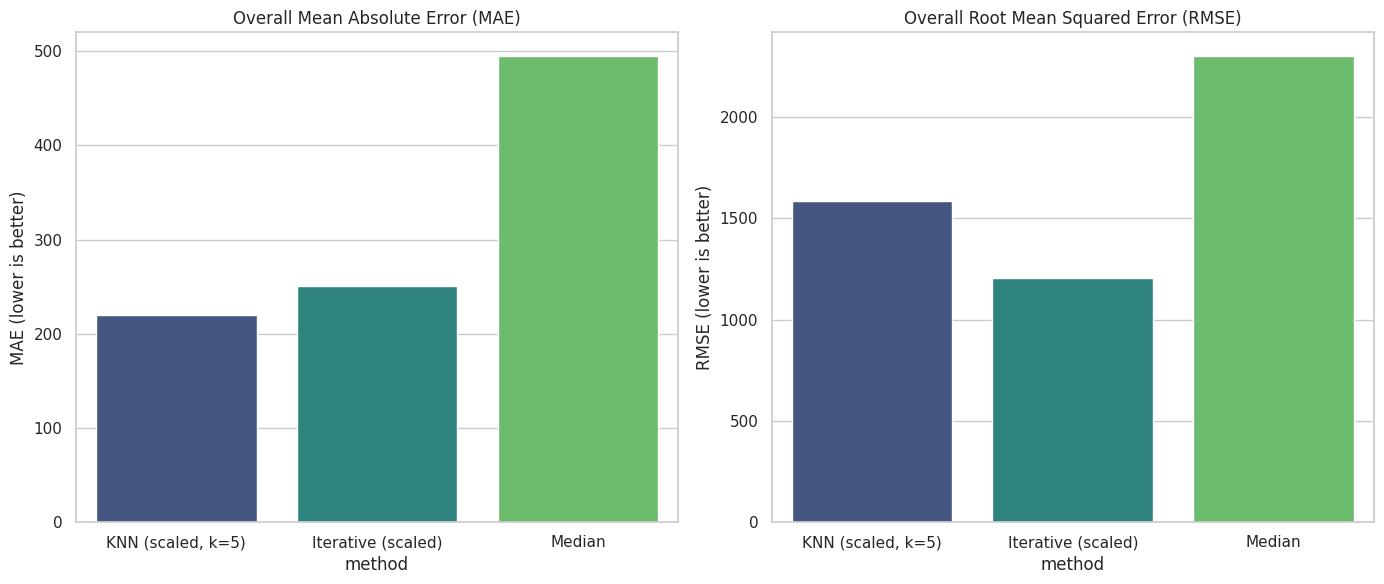


Based on the overall benchmark, the best imputation method is **KNN (scaled, k=5)** 
with the lowest overall MAE of 220.13 and RMSE of 1584.48.


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure for side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Overall MAE
sns.barplot(data=imputation_comparison, x='method', y='MAE', hue='method', legend=False, ax=axes[0], palette='viridis')
axes[0].set_title('Overall Mean Absolute Error (MAE)')
axes[0].set_ylabel('MAE (lower is better)')

# Plot Overall RMSE
sns.barplot(data=imputation_comparison, x='method', y='RMSE', hue='method', legend=False, ax=axes[1], palette='viridis')
axes[1].set_title('Overall Root Mean Squared Error (RMSE)')
axes[1].set_ylabel('RMSE (lower is better)')

plt.tight_layout()
plt.show()

# Find and print the best method
best_method = imputation_comparison.loc[imputation_comparison['MAE'].idxmin()]
print(f"\nBased on the overall benchmark, the best imputation method is **{best_method['method']}** ")
print(f"with the lowest overall MAE of {best_method['MAE']:.2f} and RMSE of {best_method['RMSE']:.2f}.")
